In [25]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import json

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.ensemble import RandomForestClassifier

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [27]:
df = pd.read_csv(r"D:\Desktop\NEUROP\NeuroPlay_Synthetic_Dataset_v2.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [28]:
df.head()
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (3600, 197)

Column Names:
['participant_id', 'age', 'age_group', 'gender', 'diagnosis_status', 'Q1_clicks', 'Q1_hits', 'Q1_misses', 'Q1_attempts', 'Q1_completion_time_ms', 'Q1_timed_out', 'Q2_clicks', 'Q2_hits', 'Q2_misses', 'Q2_attempts', 'Q2_completion_time_ms', 'Q2_timed_out', 'Q3_clicks', 'Q3_hits', 'Q3_misses', 'Q3_attempts', 'Q3_completion_time_ms', 'Q3_timed_out', 'Q4_clicks', 'Q4_hits', 'Q4_misses', 'Q4_attempts', 'Q4_completion_time_ms', 'Q4_timed_out', 'Q5_clicks', 'Q5_hits', 'Q5_misses', 'Q5_attempts', 'Q5_completion_time_ms', 'Q5_timed_out', 'Q6_clicks', 'Q6_hits', 'Q6_misses', 'Q6_attempts', 'Q6_completion_time_ms', 'Q6_timed_out', 'Q7_clicks', 'Q7_hits', 'Q7_misses', 'Q7_attempts', 'Q7_completion_time_ms', 'Q7_timed_out', 'Q8_clicks', 'Q8_hits', 'Q8_misses', 'Q8_attempts', 'Q8_completion_time_ms', 'Q8_timed_out', 'Q9_clicks', 'Q9_hits', 'Q9_misses', 'Q9_attempts', 'Q9_completion_time_ms', 'Q9_timed_out', 'Q10_clicks', 'Q10_hits', 'Q10_misses', 'Q10_attempt

In [29]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Q28_clicks                1100
Q28_hits                  1100
Q28_misses                1100
Q28_attempts              1100
Q28_completion_time_ms    1100
Q28_timed_out             1100
Q29_clicks                1100
Q29_hits                  1100
Q29_misses                1100
Q29_attempts              1100
Q29_completion_time_ms    1100
Q29_timed_out             1100
Q30_clicks                1100
Q30_hits                  1100
Q30_misses                1100
Q30_attempts              1100
Q30_completion_time_ms    1100
Q30_timed_out             1100
Q31_clicks                2400
Q31_hits                  2400
Q31_misses                2400
Q31_attempts              2400
Q31_completion_time_ms    2400
Q31_timed_out             2400
Q32_clicks                2400
Q32_hits                  2400
Q32_misses                2400
Q32_attempts              2400
Q32_completion_time_ms    2400
Q32_timed_out             2400
dtype: int64


In [30]:
print(df["age_group"].value_counts())

age_group
9-12     1300
13-17    1200
7-8      1100
Name: count, dtype: int64


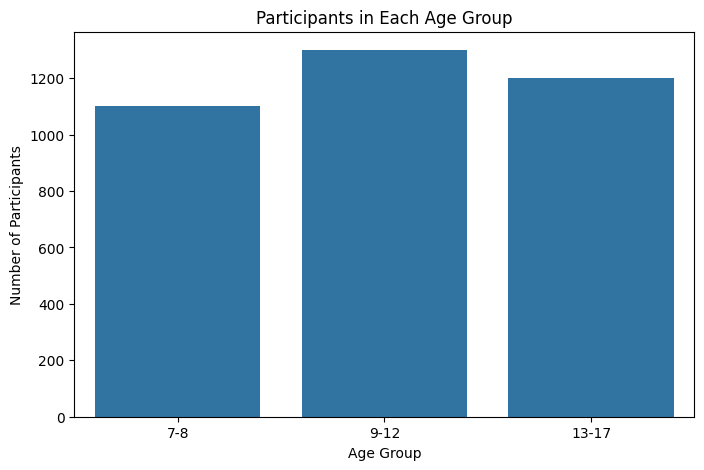

In [31]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="age_group",
    order=["7-8", "9-12", "13-17"]
)

plt.title("Participants in Each Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Participants")

plt.show()

diagnosis_status
0    2344
1    1256
Name: count, dtype: int64


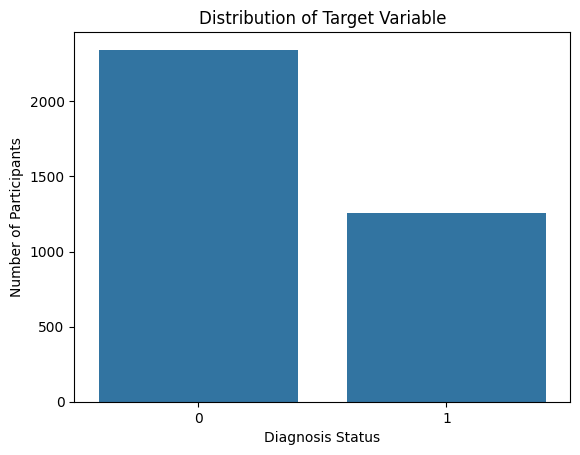

In [32]:
print(df["diagnosis_status"].value_counts())

sns.countplot(
    data=df,
    x="diagnosis_status"
)

plt.title("Distribution of Target Variable")
plt.xlabel("Diagnosis Status")
plt.ylabel("Number of Participants")

plt.show()

In [33]:
def prepare_features(group_df, question_count):

    X = pd.DataFrame(index=group_df.index)

    X["age"] = group_df["age"]

    # Exclude Q10 because it is now Pattern Matching

    for i in range(1, question_count + 1):

        if i == 10:
            continue

        clicks = group_df[f"Q{i}_clicks"]
        hits = group_df[f"Q{i}_hits"]
        misses = group_df[f"Q{i}_misses"]
        attempts = group_df[f"Q{i}_attempts"]

        completion_time = group_df[
            f"Q{i}_completion_time_ms"
        ]

        timed_out = group_df[f"Q{i}_timed_out"]

        X[f"Q{i}_clicks"] = clicks
        X[f"Q{i}_hits"] = hits
        X[f"Q{i}_misses"] = misses
        X[f"Q{i}_attempts"] = attempts

        X[f"Q{i}_completion_time_ms"] = completion_time
        X[f"Q{i}_timed_out"] = timed_out

        X[f"Q{i}_accuracy"] = (
            hits / attempts.replace(0, np.nan)
        )

        X[f"Q{i}_time_per_attempt"] = (
            completion_time / attempts.replace(0, np.nan)
        )

    # Overall performance (excluding Q10)

    question_columns = [
        i for i in range(1, question_count + 1)
        if i != 10
    ]

    total_hits = sum(
        group_df[f"Q{i}_hits"] for i in question_columns
    )

    total_misses = sum(
        group_df[f"Q{i}_misses"] for i in question_columns
    )

    total_attempts = sum(
        group_df[f"Q{i}_attempts"] for i in question_columns
    )

    total_clicks = sum(
        group_df[f"Q{i}_clicks"] for i in question_columns
    )

    total_time = sum(
        group_df[f"Q{i}_completion_time_ms"]
        for i in question_columns
    )

    total_timeouts = sum(
        group_df[f"Q{i}_timed_out"]
        for i in question_columns
    )

    X["total_hits"] = total_hits
    X["total_misses"] = total_misses
    X["total_attempts"] = total_attempts
    X["total_clicks"] = total_clicks

    X["overall_accuracy"] = (
        total_hits / total_attempts.replace(0, np.nan)
    )

    X["miss_rate"] = (
        total_misses / total_attempts.replace(0, np.nan)
    )

    X["total_completion_time_ms"] = total_time
    X["total_timeouts"] = total_timeouts

    return X

In [34]:
age_groups = {
    "7-8": 27,
    "9-12": 30,
    "13-17": 32
}

group_data = {}

for group_name, question_count in age_groups.items():

    group_df = df[
        df["age_group"] == group_name
    ].copy()

    X = prepare_features(
        group_df,
        question_count
    )

    y = group_df["diagnosis_status"].astype(int)

    group_data[group_name] = {
        "X": X,
        "y": y
    }

    print("\nAge Group:", group_name)
    print("Participants:", len(group_df))
    print("Features:", X.shape[1])
    print("Target distribution:")
    print(y.value_counts())

C:\Users\sathw\AppData\Local\Temp\ipykernel_5328\571206767.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[f"Q{i}_attempts"] = attempts
C:\Users\sathw\AppData\Local\Temp\ipykernel_5328\571206767.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[f"Q{i}_completion_time_ms"] = completion_time
C:\Users\sathw\AppData\Local\Temp\ipykernel_5328\571206767.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining a


Age Group: 7-8
Participants: 1100
Features: 217
Target distribution:
diagnosis_status
0    721
1    379
Name: count, dtype: int64

Age Group: 9-12
Participants: 1300
Features: 241
Target distribution:
diagnosis_status
0    837
1    463
Name: count, dtype: int64

Age Group: 13-17
Participants: 1200
Features: 257
Target distribution:
diagnosis_status
0    786
1    414
Name: count, dtype: int64


C:\Users\sathw\AppData\Local\Temp\ipykernel_5328\571206767.py:74: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X["total_hits"] = total_hits
C:\Users\sathw\AppData\Local\Temp\ipykernel_5328\571206767.py:75: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X["total_misses"] = total_misses
C:\Users\sathw\AppData\Local\Temp\ipykernel_5328\571206767.py:76: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at onc

In [35]:
trained_models = {}

model_metrics = {}

for group_name in age_groups:

    print("\n===================================")
    print("TRAINING AGE GROUP:", group_name)
    print("===================================")

    X = group_data[group_name]["X"]

    y = group_data[group_name]["y"]

    # Split dataset
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    # Create Random Forest pipeline
    model = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),

        (
            "random_forest",
            RandomForestClassifier(
                n_estimators=300,
                max_features="sqrt",
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    # Five-fold cross-validation
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    # Save model and feature names
    trained_models[group_name] = {
        "model": model,
        "features": list(X.columns)
    }

    # Save metrics
    model_metrics[group_name] = {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "cross_validation_mean": cv_scores.mean()
    }

    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision * 100, 2), "%")
    print("Recall:", round(recall * 100, 2), "%")
    print("F1 Score:", round(f1 * 100, 2), "%")

    print(
        "Cross Validation:",
        round(cv_scores.mean() * 100, 2),
        "%"
    )

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

print("\nAll three Random Forest models trained!")


TRAINING AGE GROUP: 7-8
Accuracy: 82.73 %
Precision: 80.65 %
Recall: 65.79 %
F1 Score: 72.46 %
Cross Validation: 81.14 %

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.92      0.87       144
           1       0.81      0.66      0.72        76

    accuracy                           0.83       220
   macro avg       0.82      0.79      0.80       220
weighted avg       0.83      0.83      0.82       220


TRAINING AGE GROUP: 9-12
Accuracy: 80.0 %
Precision: 73.56 %
Recall: 68.82 %
F1 Score: 71.11 %
Cross Validation: 82.31 %

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.85       167
           1       0.74      0.69      0.71        93

    accuracy                           0.80       260
   macro avg       0.78      0.78      0.78       260
weighted avg       0.80      0.80      0.80       260


TRAINING AGE GROUP: 13-17
Accuracy: 84.17 %
Precision

In [36]:
metrics_df = pd.DataFrame(model_metrics).T

metrics_df = metrics_df * 100

metrics_df = metrics_df.round(2)

metrics_df

,accuracy,precision,recall,f1_score,cross_validation_mean
7-8,82.73,80.65,65.79,72.46,81.14
9-12,80.00,73.56,68.82,71.11,82.31
13-17,84.17,76.47,78.31,77.38,80.73


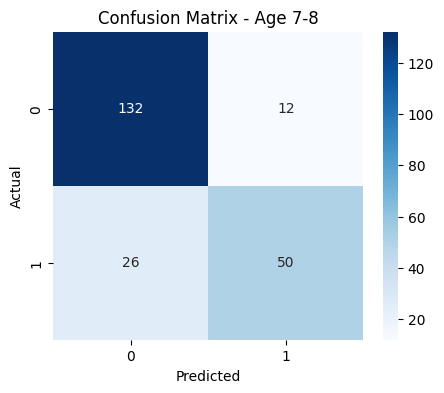

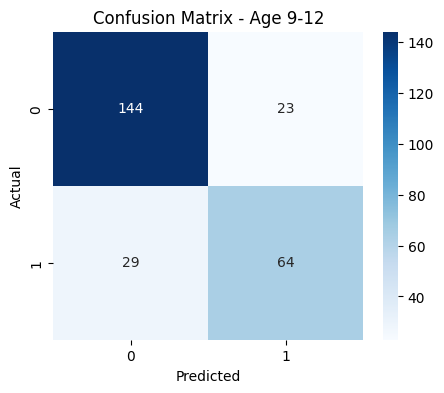

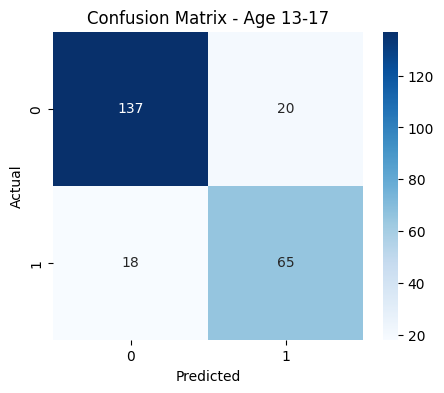

In [37]:
for group_name in age_groups:

    X = group_data[group_name]["X"]
    y = group_data[group_name]["y"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    model = trained_models[group_name]["model"]

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - Age {group_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

In [38]:
import joblib

# Save all three trained Random Forest models
joblib.dump(
    trained_models,
    r"D:\Desktop\NEUROP\neuroplay_models.joblib"
)

print("Updated Random Forest models saved successfully!")

Updated Random Forest models saved successfully!


In [39]:
import joblib

loaded_models = joblib.load("neuroplay_models.joblib")

print("Models loaded successfully!")

print("\nAvailable age groups:")

for group in loaded_models:
    print(group)

Models loaded successfully!

Available age groups:
7-8
9-12
13-17


In [40]:
import json

with open("neuroplay_metrics.json", "w") as file:
    json.dump(model_metrics, file, indent=4)

print("Model evaluation metrics saved successfully!")

Model evaluation metrics saved successfully!


In [41]:
import joblib

trained_models = joblib.load("neuroplay_models.joblib")

for age_group, details in trained_models.items():

    print("\nAge Group:", age_group)

    print("Features required:")

    print(details["features"])


Age Group: 7-8
Features required:
['age', 'Q1_clicks', 'Q1_hits', 'Q1_misses', 'Q1_attempts', 'Q1_completion_time_ms', 'Q1_timed_out', 'Q1_accuracy', 'Q1_time_per_attempt', 'Q2_clicks', 'Q2_hits', 'Q2_misses', 'Q2_attempts', 'Q2_completion_time_ms', 'Q2_timed_out', 'Q2_accuracy', 'Q2_time_per_attempt', 'Q3_clicks', 'Q3_hits', 'Q3_misses', 'Q3_attempts', 'Q3_completion_time_ms', 'Q3_timed_out', 'Q3_accuracy', 'Q3_time_per_attempt', 'Q4_clicks', 'Q4_hits', 'Q4_misses', 'Q4_attempts', 'Q4_completion_time_ms', 'Q4_timed_out', 'Q4_accuracy', 'Q4_time_per_attempt', 'Q5_clicks', 'Q5_hits', 'Q5_misses', 'Q5_attempts', 'Q5_completion_time_ms', 'Q5_timed_out', 'Q5_accuracy', 'Q5_time_per_attempt', 'Q6_clicks', 'Q6_hits', 'Q6_misses', 'Q6_attempts', 'Q6_completion_time_ms', 'Q6_timed_out', 'Q6_accuracy', 'Q6_time_per_attempt', 'Q7_clicks', 'Q7_hits', 'Q7_misses', 'Q7_attempts', 'Q7_completion_time_ms', 'Q7_timed_out', 'Q7_accuracy', 'Q7_time_per_attempt', 'Q8_clicks', 'Q8_hits', 'Q8_misses', 'Q8

In [42]:
for group, data in trained_models.items():

    print("\nAge Group:", group)

    print("Q10 Features:")

    print([
        feature
        for feature in data["features"]
        if feature.startswith("Q10_")
    ])


Age Group: 7-8
Q10 Features:
[]

Age Group: 9-12
Q10 Features:
[]

Age Group: 13-17
Q10 Features:
[]


In [43]:
import joblib

saved_models = joblib.load("neuroplay_models.joblib")

for group, details in saved_models.items():
    print(group, ":", len(details["features"]), "features")

7-8 : 217 features
9-12 : 241 features
13-17 : 257 features
